## **Brain volume and dementia (OASIS)**

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

* **Dataset:** [Kaggle – MRI and Alzheimer's](https://www.kaggle.com/datasets/jboysen/mri-and-alzheimers/data)

* **License & Terms:** [OASIS Brains Project](https://sites.wustl.edu/oasisbrains/)

* **Acknowledgment:** Data were provided in part by OASIS: OASIS-2: Longitudinal: Principal Investigators: D. Marcus, R. Buckner, J. Csernansky, J. Morris; P50 AG05681, P01 AG03991, P01 AG026276, R01 AG021910, P20 MH071616, U24 RR021382.

* **Citation:** Marcus, D. S., Fotenos, A. F., Csernansky, J. G., Morris, J. C., & Buckner, R. L. (2010). Open Access Series of Imaging Studies (OASIS): Longitudinal MRI Data in Nondemented and Demented Older Adults. *Journal of Cognitive Neuroscience*, 22(12), 2677–2684. `doi: 10.1162/jocn.2009.21407`

### **1. Data Overview**

In [2]:
df = pd.read_csv("data/oasis_longitudinal.csv")
df.shape

(373, 15)

In [3]:
df.head()

,Subject ID,MRI ID,Group,Visit,MR Delay,M/F,Hand,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
0,OAS2_0001,OAS2_0001_MR1,Nondemented,1,0,M,R,87,14,2.0,27.0,0.0,1987,0.696,0.883
1,OAS2_0001,OAS2_0001_MR2,Nondemented,2,457,M,R,88,14,2.0,30.0,0.0,2004,0.681,0.876
2,OAS2_0002,OAS2_0002_MR1,Demented,1,0,M,R,75,12,NaN,23.0,0.5,1678,0.736,1.046
3,OAS2_0002,OAS2_0002_MR2,Demented,2,560,M,R,76,12,NaN,28.0,0.5,1738,0.713,1.010
4,OAS2_0002,OAS2_0002_MR3,Demented,3,1895,M,R,80,12,NaN,22.0,0.5,1698,0.701,1.034


In [4]:
df.tail()

,Subject ID,MRI ID,Group,Visit,MR Delay,M/F,Hand,Age,EDUC,SES,MMSE,CDR,eTIV,nWBV,ASF
368,OAS2_0185,OAS2_0185_MR2,Demented,2,842,M,R,82,16,1.0,28.0,0.5,1693,0.694,1.037
369,OAS2_0185,OAS2_0185_MR3,Demented,3,2297,M,R,86,16,1.0,26.0,0.5,1688,0.675,1.040
370,OAS2_0186,OAS2_0186_MR1,Nondemented,1,0,F,R,61,13,2.0,30.0,0.0,1319,0.801,1.331
371,OAS2_0186,OAS2_0186_MR2,Nondemented,2,763,F,R,63,13,2.0,30.0,0.0,1327,0.796,1.323
372,OAS2_0186,OAS2_0186_MR3,Nondemented,3,1608,F,R,65,13,2.0,30.0,0.0,1333,0.801,1.317


In [5]:
print(df["Group"].value_counts())

Group
Nondemented    190
Demented       146
Converted       37
Name: count, dtype: int64


In [6]:
print(df["Visit"].value_counts())

Visit
1    150
2    144
3     58
4     15
5      6
Name: count, dtype: int64


In [7]:
print(df["M/F"].value_counts())

M/F
F    213
M    160
Name: count, dtype: int64


In [8]:
print("How many patients visited 2, 3, 4, or 5 times")

print(df["Subject ID"].value_counts().value_counts().sort_index())

How many patients visited 2, 3, 4, or 5 times
count
2    94
3    43
4     9
5     4
Name: count, dtype: int64


In [9]:
is_all_right_handed = (df["Hand"] == "R").all()
print(is_all_right_handed)

True


In [10]:
df = df.rename(columns={
    "Subject ID": "subject_id",
    "MRI ID": "mri_id",
    "Group": "group",
    "Visit": "visit",
    "MR Delay": "mr_delay",
    "M/F": "sex",
    "Hand": "hand",
    "Age": "age",
    "EDUC": "educ",
    "SES": "ses",
    "MMSE": "mmse",
    "CDR": "cdr",
    "eTIV": "etiv",
    "nWBV": "nwbv",
    "ASF": "asf",
})

### **2. Data Cleaning**

In [11]:
df = df.drop(columns =["hand"])
print(df.shape)

(373, 14)


In [12]:
print(df[df.isna().any(axis=1)])

    subject_id         mri_id     group  visit  mr_delay sex  age  educ  ses  \
2    OAS2_0002  OAS2_0002_MR1  Demented      1         0   M   75    12  NaN   
3    OAS2_0002  OAS2_0002_MR2  Demented      2       560   M   76    12  NaN   
4    OAS2_0002  OAS2_0002_MR3  Demented      3      1895   M   80    12  NaN   
10   OAS2_0007  OAS2_0007_MR1  Demented      1         0   M   71    16  NaN   
11   OAS2_0007  OAS2_0007_MR3  Demented      3       518   M   73    16  NaN   
12   OAS2_0007  OAS2_0007_MR4  Demented      4      1281   M   75    16  NaN   
134  OAS2_0063  OAS2_0063_MR1  Demented      1         0   F   80    12  NaN   
135  OAS2_0063  OAS2_0063_MR2  Demented      2       490   F   81    12  NaN   
207  OAS2_0099  OAS2_0099_MR1  Demented      1         0   F   80    12  NaN   
208  OAS2_0099  OAS2_0099_MR2  Demented      2       807   F   83    12  NaN   
237  OAS2_0114  OAS2_0114_MR1  Demented      1         0   F   76    12  NaN   
238  OAS2_0114  OAS2_0114_MR2  Demented 

In [13]:
print(df[["ses", "mmse"]].isna().sum())

ses     19
mmse     2
dtype: int64


There are two missing values in the Mini-Mental State Examination column and 19 in the Socioeconomic Status column.

SES did not change throughout the study, so these values can be filled in if they were known from other visits. If the value was missing for all visits, those rows need to be deleted.

Since MMSE changed from visit to visit, the two rows with missing values need to be deleted.

In [14]:
df.loc[df["ses"].isna(), "subject_id"].unique()

array(['OAS2_0002', 'OAS2_0007', 'OAS2_0063', 'OAS2_0099', 'OAS2_0114',
       'OAS2_0160', 'OAS2_0181', 'OAS2_0182'], dtype=object)

In [15]:
# chronological order
df = df.sort_values(["subject_id", "visit"])

# find first filled ses value for unique subject id and fill in the rest
df["ses"] = df["ses"].fillna(df.groupby("subject_id")["ses"].transform("first"))

In [16]:
df_cleaned = df.dropna(subset=["ses", "mmse"]).copy()

In [17]:
# check for the missing values
print("Remaining missing values:\n", df_cleaned[["ses", "mmse"]].isna().sum())
print(f"Rows before: {len(df)}, Rows after: {len(df_cleaned)}")

Remaining missing values:
 ses     0
mmse    0
dtype: int64
Rows before: 373, Rows after: 354


In [18]:
print(df_cleaned["visit"].value_counts())

visit
1    142
2    137
3     55
4     14
5      6
Name: count, dtype: int64


In [19]:
# baseline df with first visits

df_baseline = df_cleaned[df_cleaned["visit"] == 1].copy()

In [20]:
df_baseline.shape

(142, 14)

In [21]:
df_baseline.to_csv("data/oasis_baseline.csv", index=False)

### 3. Data visualisation

In [22]:
import os

os.makedirs("figures", exist_ok=True) # creates figures folder if it doesn't exist yet

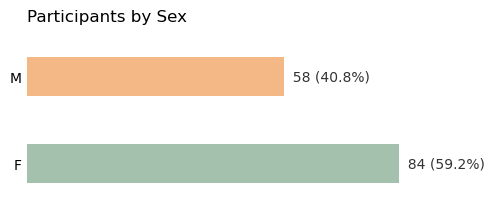

In [23]:
counts = df_baseline["sex"].value_counts()

ax = counts.plot.barh(
    color=["#A3C1AD", "#F4B886"], width=0.45, figsize=(6, 2.2)
)

ax.bar_label(
    ax.containers[0],
    labels=[f'  {v} ({v/counts.sum():.1%})' for v in counts],
    color="#333333",
)
ax.set(xlim=(0, counts.max() * 1.25), ylabel="")
ax.set_title("Participants by Sex", loc="left", pad=10)
ax.xaxis.set_visible(False)
ax.tick_params(axis="y", length=0)
ax.spines[:].set_visible(False)
plt.savefig("figures/participants_by_sex.png", dpi=150, bbox_inches="tight")

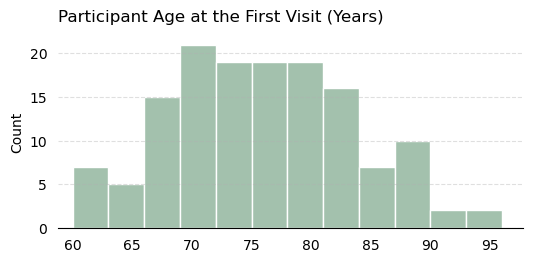

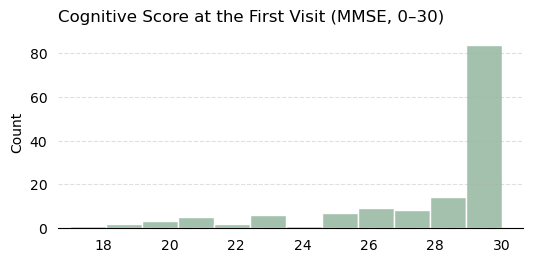

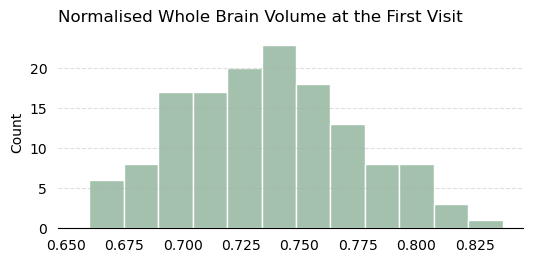

In [24]:
titles = {
    "age": "Participant Age at the First Visit (Years)",
    "mmse": "Cognitive Score at the First Visit (MMSE, 0–30)",
    "nwbv": "Normalised Whole Brain Volume at the First Visit",
}

for col, title in titles.items():
  ax = df_baseline[col].plot.hist(
      bins=12, color="#A3C1AD", edgecolor="white", figsize=(6, 2.5)
  )
  ax.set(xlabel="", ylabel="Count", xlim=(df_baseline[col].min() * 0.98, None))
  ax.set_title(title, loc="left", pad=10)
  ax.tick_params(length=0, pad=8)
  ax.spines[["top", "right", "left"]].set_visible(False)
  ax.grid(axis="y", linestyle="--", alpha=0.4)
  plt.savefig(f"figures/hist_{col.lower()}.png", dpi=150, bbox_inches="tight")
  plt.show()